In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
t = pd.read_csv('Data/train-2025.csv')

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_72814/2212294594.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv('Data/train-2025.csv')


In [ ]:
t.head()

,Unnamed: 0,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,...,inc_extraord,taxes,profit,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations
0,17,520288,2011-12-31,28.0,SRL,14.0,NaN,2011,67537.0,1137566.0,...,-309.0,-80959.0,-81288.0,NaN,6318.0,-3.81,-28.03,496258.0,-917029.0,-849.0
1,18,520288,2008-12-31,28.0,SRL,14.0,NaN,2008,256438.0,1181416.0,...,-678.0,-94622.0,-107382.0,NaN,46088.0,-2.76,NaN,97952.0,NaN,-3881.0
2,19,520288,2009-12-31,28.0,SRL,14.0,NaN,2009,194046.0,1152014.0,...,4224.0,-74235.0,-77819.0,NaN,67611.0,-2.17,NaN,-210671.0,NaN,32618.0
3,21,520288,2012-12-31,28.0,SRL,14.0,NaN,2012,15195.0,1116938.0,...,3634.0,-250786.0,-250786.0,NaN,-161478.0,-12.99,NaN,367892.0,-1094962.0,-168907.0
4,22,520288,2007-12-31,28.0,SRL,14.0,NaN,2007,126603.0,1127807.0,...,820.0,92192.0,36733.0,NaN,153060.0,6.20,52.43,-317007.0,-1184970.0,80039.0


In [35]:
tt1 = t[['fs_year','def_date']].dropna().groupby('fs_year').agg({'def_date':'count'}).reset_index()
tt2 = t[['fs_year','id']].groupby('fs_year').agg({'id':'count'}).reset_index()
tt = tt1.merge(tt2)
tt['ER'] = tt['def_date'] / tt['id'] * 100
tt

,fs_year,def_date,id,ER
0,2007,12499,144528,8.648151
1,2008,11928,161863,7.369195
2,2009,9740,171150,5.690914
3,2010,6531,175399,3.723510
4,2011,3377,184973,1.825672
5,2012,650,185639,0.350142


In [68]:
df = pd.read_csv('train_demo_subset.csv')
# df = df.drop_duplicates(subset=['id'])

df['default'] = 0
df.loc[~df['def_date'].str.contains('99', na=False), 'default'] = 1
df.shape[0], df['default'].sum(), df['default'].mean()*100

(1000, np.int64(93), np.float64(9.3))

In [66]:
df.columns

Index(['Unnamed: 0', 'id', 'stmt_date', 'HQ_city', 'legal_struct',
       'ateco_sector', 'def_date', 'fs_year', 'asst_intang_fixed',
       'asst_tang_fixed', 'asst_fixed_fin', 'asst_current', 'AR',
       'cash_and_equiv', 'asst_tot', 'eqty_tot', 'eqty_corp_family_tot',
       'liab_lt', 'liab_lt_emp', 'debt_bank_st', 'debt_bank_lt', 'debt_fin_st',
       'debt_fin_lt', 'AP_st', 'AP_lt', 'debt_st', 'debt_lt', 'rev_operating',
       'COGS', 'prof_operations', 'goodwill', 'inc_financing', 'exp_financing',
       'prof_financing', 'inc_extraord', 'taxes', 'profit', 'days_rec',
       'ebitda', 'roa', 'roe', 'wc_net', 'margin_fin', 'cf_operations',
       'default'],
      dtype='object')

In [84]:
df.groupby(['ateco_sector']).agg({'id':'count','default':'mean'}).reset_index().sort_values(by='id', ascending=False).query('id >= 10')

,ateco_sector,id,default
47,68,186,0.091398
30,41,151,0.112583
34,46,104,0.086538
16,25,56,0.125000
35,47,45,0.066667
19,28,36,0.055556
33,45,35,0.000000
14,23,22,0.000000
32,43,22,0.045455
3,10,20,0.150000


In [55]:
df.drop_duplicates(subset=['id']).shape[0], df.drop_duplicates(subset=['id'])['default'].sum()

(977, np.int64(70))

In [56]:
from datetime import datetime, timedelta

In [57]:
def days_diff(d1, d2):
    if isinstance(d1, str): d1 = datetime.strptime(d1, '%Y-%m-%d')
    if isinstance(d2, str): d2 = datetime.strptime(d2, '%Y-%m-%d')
    return (d1 - d2).days

In [58]:
df.groupby('ateco_sector').agg({'default':'sum'}).reset_index().query('default == 0').shape

(38, 2)

In [65]:
df.query('default==1').groupby(['fs_year', 'stmt_date','def_date']).agg({'id':'count'})

id
fs_year stmt_date def_date    
2007    12/31/07  2/11/11    3
                  2/9/11     7
                  5/27/09    2
                  6/7/10     2
                  8/12/10    3
                  8/9/10     7
2008    12/31/08  2/15/11    7
                  2/9/11     8
                  5/27/09    3
                  6/7/10     1
                  8/11/10    5
                  8/6/10     8
2009    12/31/09  2/15/11    4
                  2/7/11     7
                  2/9/11     7
                  8/11/10    5
                  8/6/10     4
                  8/7/10     1
2010    12/31/10  2/7/11     2
                  2/9/11     3
                  5/11/12    1
2011    12/31/11  5/11/12    3

In [32]:
temp = df.query('default==1 and fs_year == 2008')[['stmt_date','def_date','fs_year']]
# print(temp.head(10))
temp['stmt_date'] = pd.to_datetime(temp['stmt_date'], format='%m/%d/%y')
temp['def_date'] = pd.to_datetime(temp['def_date'], format='%m/%d/%y')
# print(temp.head(10))
temp['months_to_default'] = temp.apply(lambda x: np.round(days_diff(x['def_date'], x['stmt_date'])/30), axis=1)
temp

,stmt_date,def_date,fs_year,months_to_default
243,2008-12-31,2010-08-11,2008,20.0
249,2008-12-31,2010-08-06,2008,19.0
253,2008-12-31,2010-08-06,2008,19.0
265,2008-12-31,2011-02-09,2008,26.0
266,2008-12-31,2011-02-15,2008,26.0
271,2008-12-31,2011-02-15,2008,26.0
277,2008-12-31,2010-08-06,2008,19.0
278,2008-12-31,2010-08-11,2008,20.0
280,2008-12-31,2010-08-11,2008,20.0
284,2008-12-31,2010-08-11,2008,20.0


In [11]:
df.query('id == 4096740966')

,Unnamed: 0,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,...,taxes,profit,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations,default
243,4491867,4096740966,12/31/08,15,SPA,68,8/11/10,2008,1015794,252,...,-208056,-181737,-190.04,-452806,-6.33,-3.19,4832494,4673635.0,-174753,1


In [5]:
df.query('default==1 and def_date.str.contains("08")')[['stmt_date','def_date','fs_year']]

,stmt_date,def_date,fs_year


In [5]:
df['stmt_date'] = pd.to_datetime(df['stmt_date'], format='%m/%d/%y')
df['def_date'] = pd.to_datetime(df['def_date'], format='%m/%d/%y')
df['def_within_1_year'] = ((df['def_date'] - df['stmt_date']).abs() <= pd.Timedelta(days=365)).astype(int)
df['def_eventually'] = (df['default'] * (1 - df['def_within_1_year']))

In [6]:
df.query('default==1').groupby(['fs_year']).agg({'id':'count'}).reset_index().rename(columns={'id':'def'})

,fs_year,def
0,2007,24
1,2008,32
2,2009,28
3,2010,6
4,2011,3


In [7]:
df.groupby(['fs_year']).agg({'id':'count'}).reset_index().merge(
    df.query('default==1').groupby(['fs_year']).agg({'id':'count'}).reset_index().rename(columns={'id':'def'}), on=['fs_year'], how='left'
).merge(
    df.query('default==1 and def_within_1_year == 1').groupby(['fs_year']).agg({'id':'count'}).reset_index().rename(columns={'id':'def_1yr'}), on=['fs_year'], how='left'
)

,fs_year,id,def,def_1yr
0,2007,241,24.0,NaN
1,2008,177,32.0,3.0
2,2009,111,28.0,10.0
3,2010,116,6.0,5.0
4,2011,134,3.0,3.0
5,2012,221,NaN,NaN


In [8]:
df.groupby(['fs_year','default','def_within_1_year']).agg({'id':'count'}).reset_index()

,fs_year,default,def_within_1_year,id
0,2007,0,0,217
1,2007,1,0,24
2,2008,0,0,145
3,2008,1,0,29
4,2008,1,1,3
5,2009,0,0,83
6,2009,1,0,18
7,2009,1,1,10
8,2010,0,0,110
9,2010,1,0,1


In [9]:
df.drop_duplicates(subset=['id']).groupby(['default']).agg({'id':['count']})

,id
,count
default,
0,907
1,70


In [10]:
df.shape[0], df.drop_duplicates(subset=['id']).shape[0], df.drop_duplicates(subset=['id'])['default'].sum()

(1000, 977, np.int64(70))

In [11]:
df.query('eqty_tot <= 0').groupby('default').agg({'id':'count'})

,id
default,
0,35
1,31


In [14]:
feature_cols = ['asst_intang_fixed', 'asst_tang_fixed', 'asst_fixed_fin', 'asst_current', 'AR', 
 'cash_and_equiv', 'asst_tot', 'eqty_tot', 'eqty_corp_family_tot',
 'liab_lt', 'liab_lt_emp', 'debt_bank_st', 'debt_bank_lt', 'debt_fin_st',
 'debt_fin_lt', 'AP_st', 'AP_lt', 'debt_st', 'debt_lt', 'rev_operating',
 'COGS', 'prof_operations', 'goodwill', 'inc_financing', 'exp_financing',
 'prof_financing', 'inc_extraord', 'taxes', 'profit',
 'ebitda', 'roa', 'roe', 'wc_net', 'margin_fin', 'cf_operations','days_rec']
len(feature_cols)

36

In [12]:
df['asst_tot'].min(), df['asst_tot'].max()

(np.int64(1501074), np.int64(3768182000))

In [21]:
df[feature_cols].describe()

,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,eqty_tot,eqty_corp_family_tot,liab_lt,...,inc_extraord,taxes,profit,ebitda,roa,roe,wc_net,margin_fin,cf_operations,days_rec
count,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,0.0,1.000000e+03,...,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1000.000000,897.000000,1.000000e+03,9.340000e+02,1.000000e+03,306.000000
mean,3.707548e+05,2.987731e+06,4.825433e+05,9.136494e+06,6.684854e+06,4.217105e+05,1.308282e+07,2.651435e+06,NaN,2.669153e+05,...,4.984279e+04,1.482435e+05,-4.521104e+04,7.740530e+05,2.827090,4.895764,1.280969e+06,-1.120229e+06,4.651772e+05,88.843824
std,3.618504e+06,1.574998e+07,3.014022e+06,1.165180e+08,1.155431e+08,1.614698e+06,1.216547e+08,7.665709e+06,NaN,3.159528e+06,...,5.013220e+05,1.908155e+06,2.387931e+06,9.125207e+06,11.095338,28.259318,6.304296e+06,1.452545e+07,6.999612e+06,157.357094
min,0.000000e+00,0.000000e+00,-7.382000e+03,2.771000e+03,-3.545000e+05,-1.926120e+05,1.501074e+06,-2.267327e+07,NaN,0.000000e+00,...,-1.042736e+06,-2.842284e+07,-5.448900e+07,-8.517481e+06,-105.780000,-147.630000,-5.869924e+07,-2.937889e+08,-2.821161e+07,-332.630000
25%,2.062500e+02,8.213800e+04,0.000000e+00,1.285381e+06,2.800590e+05,6.322500e+03,2.263806e+06,1.479558e+05,NaN,0.000000e+00,...,-4.350000e+01,-1.418650e+04,-2.991600e+04,4.161050e+04,0.170000,-1.450000,-1.459558e+05,-1.020287e+06,2.051250e+03,6.115000
50%,8.433500e+03,6.701070e+05,1.500000e+03,2.185182e+06,1.013905e+06,5.289450e+04,3.712324e+06,7.200505e+05,NaN,0.000000e+00,...,0.000000e+00,4.237000e+04,8.459500e+03,1.682340e+05,2.430000,2.790000,4.089485e+05,-9.055800e+04,8.167700e+04,61.180000
75%,7.381575e+04,2.161138e+06,5.063925e+04,4.718422e+06,2.235556e+06,2.588570e+05,7.471380e+06,2.305531e+06,NaN,2.713925e+04,...,7.306500e+03,1.995100e+05,9.993775e+04,4.374938e+05,5.582500,13.920000,1.575122e+06,3.780298e+05,2.722840e+05,157.650000
max,8.168651e+07,3.824453e+08,6.247341e+07,3.667707e+09,3.643927e+09,2.378000e+07,3.768182e+09,1.116108e+08,NaN,9.634400e+07,...,1.113007e+07,1.792784e+07,1.377811e+07,2.833520e+08,91.030000,96.700000,1.037240e+08,5.616589e+07,2.152570e+08,1478.800000


In [23]:
skew = pd.DataFrame(df[feature_cols].skew()).reset_index()
skew.columns = ['features','skew']
skew.sort_values(by='skew',ascending=False).head(10)

,features,skew
20,COGS,31.362898
19,rev_operating,31.354657
4,AR,31.295207
3,asst_current,31.061269
17,debt_st,31.002314
29,ebitda,29.821296
6,asst_tot,29.606168
34,cf_operations,28.946594
22,goodwill,28.690736
24,exp_financing,28.610439


In [24]:
temp = df[['asst_tot','COGS']]
temp['asst_tot'] = np.log1p(temp['asst_tot'])
temp['COGS'] = np.log1p(temp['COGS'])
temp.skew()

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_15126/2983297834.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['asst_tot'] = np.log1p(temp['asst_tot'])
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_15126/2983297834.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  

asst_tot    1.482795
COGS       -0.735288
dtype: float64

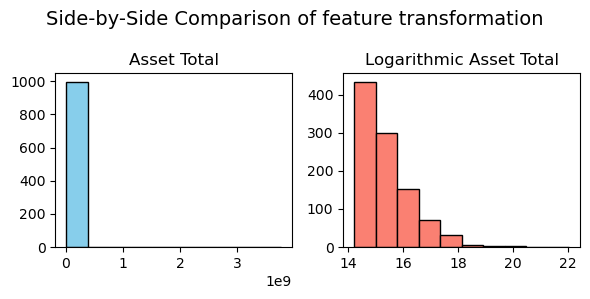

In [40]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(6, 3))
ax1.hist(df['asst_tot'], color='skyblue', edgecolor='black')
ax1.set_title('Asset Total')

ax2.hist(temp['asst_tot'], color='salmon', edgecolor='black')
ax2.set_title('Logarithmic Asset Total')

plt.suptitle('Side-by-Side Comparison of feature transformation', fontsize=14)
plt.tight_layout()
plt.show()

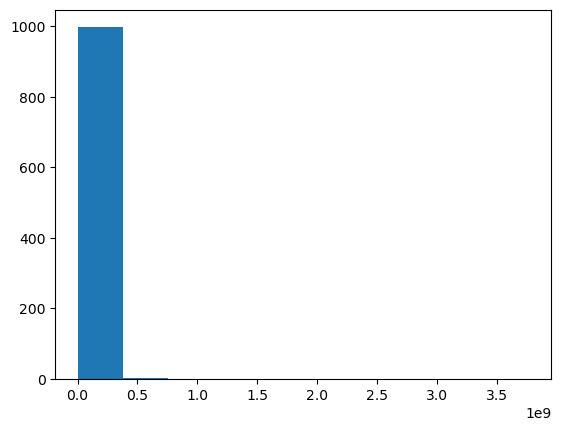

In [30]:
plt.hist(df['asst_tot'])
plt.show()

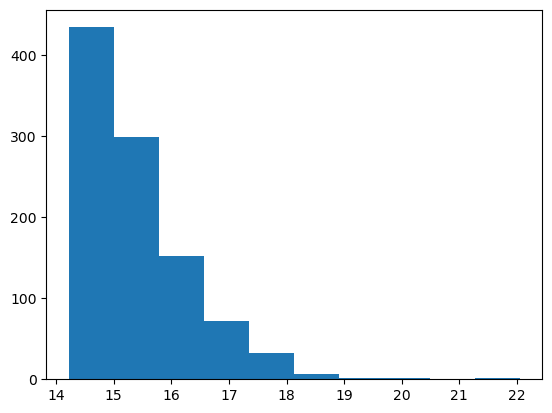

In [31]:
plt.hist(temp['asst_tot'])
plt.show()

In [43]:
pd.DataFrame(df[feature_cols].isna().sum())

,0
asst_intang_fixed,0
asst_tang_fixed,0
asst_fixed_fin,0
asst_current,0
AR,0
cash_and_equiv,0
asst_tot,0
eqty_tot,0
eqty_corp_family_tot,1000
liab_lt,0


In [44]:
# features['ratio_prof_operations_rev_operating'] = features['prof_operations'] / features['rev_operating']
# features['ratio_eqty_tot_eqty_tot'] = features['eqty_tot'] / features['eqty_tot']
# features['ratio_cf_operations_debt_st'] = features['cf_operations'] / features['debt_st']
# features['ratio_cf_operations_debt_st'] = (features['debt_bank_st'] + features['debt_bank_lt']) / features['asst_tot']

In [45]:
def IV(df, feature, target, bins=10, adjustment=0.5):
    data = df[[feature, target]].copy()                  # .copy() avoids SettingWithCopyWarning
    data["bin"] = pd.qcut(data[feature], q=bins, duplicates="drop")

    t = (data.groupby("bin", observed=True)[target]
             .agg(total="count", bad="sum")
             .reset_index())                              # keeps "bin" as a column
    t["good"] = t["total"] - t["bad"]

    total_good, total_bad = t["good"].sum(), t["bad"].sum()
    if total_good == 0 or total_bad == 0:
        raise ValueError("Target must contain both classes.")

    t["pct_good"] = (t["good"] + adjustment) / (total_good + adjustment * len(t))
    t["pct_bad"]  = (t["bad"]  + adjustment) / (total_bad  + adjustment * len(t))
    t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
    t["iv"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
    t["bad_rate"] = t["bad"] / t["total"]

    # optional: numeric bin edges, handy for applying the same cutoffs to new data
    t["lower"] = t["bin"].apply(lambda i: i.left)
    t["upper"] = t["bin"].apply(lambda i: i.right)

    return t["iv"].sum(), t                               # no second reset_index

In [46]:
# feature_cols = ['ratio_prof_operations_rev_operating', 'ratio_eqty_tot_eqty_tot', 'ratio_cf_operations_debt_st', 'ratio_cf_operations_debt_st']

In [47]:
# iv, iv_bins = IV(features, 'roa', 'default')
# print(iv)
# iv_bins

In [48]:
# iv, iv_bins = IV(features, 'eqty_tot', 'default')
# print(iv)
# iv_bins

In [49]:
years = [2007,2008,2009,2010,2011]

In [77]:
imp_dfs = []
for y in years:
    processed_feats, ivs, iv_bins = [], [], []
    print(y)
    for f in feature_cols:
        try:
            iv, iv_bin = IV(df.query(f'fs_year == {y}'), f, 'default')
            processed_feats.append(f)
            ivs.append(iv)
            iv_bins.append(iv_bins)
            # print(f"{f} Passed")
        except:
            print(f"{f} Failed")
    d = pd.DataFrame(zip(processed_feats, ivs), columns=["feature", f"iv_{y}"]).sort_values(by=f"iv_{y}", ascending=False).reset_index(drop=True)
    imp_dfs.append(d)

2007
eqty_corp_family_tot Failed
2008
eqty_corp_family_tot Failed
2009
eqty_corp_family_tot Failed
2010
eqty_corp_family_tot Failed
roe Failed
2011
eqty_corp_family_tot Failed
roe Failed


In [83]:
imp_dfs[0].merge(imp_dfs[1], on=['feature']).merge(imp_dfs[2], on=['feature']).merge(imp_dfs[3], on=['feature']).merge(imp_dfs[4], on=['feature']).head(15)

,feature,iv_2007,iv_2008,iv_2009,iv_2010,iv_2011
0,cf_operations,1.555116,0.556398,1.012099,0.952423,0.752841
1,liab_lt_emp,1.393348,0.034583,0.570395,0.212050,0.472106
2,asst_tang_fixed,1.375349,0.202231,1.327204,0.652732,0.244578
3,goodwill,1.199694,0.858321,0.499219,0.652732,0.752841
4,eqty_tot,1.172635,0.653787,2.199120,0.933497,0.475241
5,ebitda,0.887114,1.074210,0.748878,0.952423,0.493829
6,margin_fin,0.826425,0.529091,0.414991,0.271574,0.170057
7,taxes,0.822197,0.564175,0.764575,0.952423,0.752841
8,profit,0.705666,0.862158,0.883472,0.933497,0.752841
9,prof_operations,0.679375,0.837194,0.727852,0.952423,0.493829


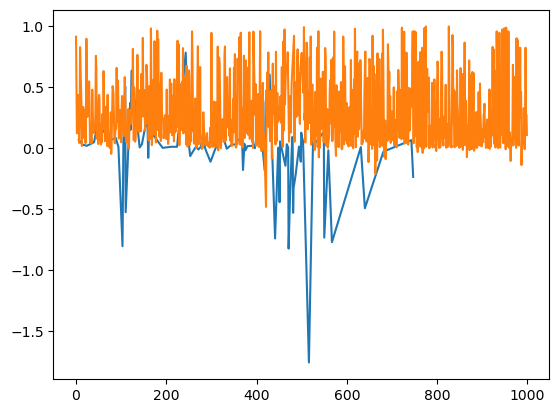

In [5]:
plt.plot(temp.query('default==1')['ratio'])
plt.plot(temp.query('default==0')['ratio'])

In [23]:
iv, iv_bins = IV(temp, 'ratio', 'default')
print(iv)
iv_bins

1.2848249236859863


/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_22628/2195389345.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["bin"] = binned.astype(object)


,index,bin,total,bad,good,pct_good,pct_bad,woe,iv,bad_rate
0,0,"(-1.761, 0.00653]",100,36,64,0.070724,0.372449,-1.661320,0.501262,0.36
1,1,"(0.00653, 0.0308]",100,16,84,0.092654,0.168367,-0.597281,0.045222,0.16
2,2,"(0.0308, 0.0646]",100,15,85,0.093750,0.158163,-0.522996,0.033688,0.15
3,3,"(0.0646, 0.121]",100,11,89,0.098136,0.117347,-0.178781,0.003435,0.11
4,4,"(0.121, 0.183]",100,6,94,0.103618,0.066327,0.446125,0.016637,0.06
5,5,"(0.183, 0.269]",100,3,97,0.106908,0.035714,1.096417,0.078058,0.03
6,6,"(0.269, 0.372]",100,1,99,0.109101,0.015306,1.964020,0.184215,0.01
7,7,"(0.372, 0.513]",100,2,98,0.108004,0.025510,1.443093,0.119047,0.02
8,8,"(0.513, 0.699]",100,2,98,0.108004,0.025510,1.443093,0.119047,0.02
9,9,"(0.699, 0.999]",100,1,99,0.109101,0.015306,1.964020,0.184215,0.01


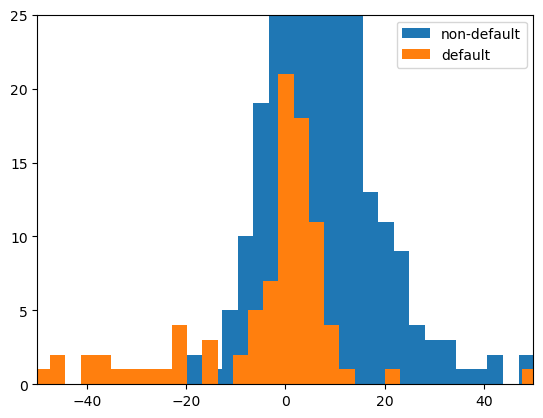

In [9]:
plt.hist(df.query('default==0')['roa'], bins=51, label='non-default')
plt.hist(df.query('default==1')['roa'], bins=51, label='default')
plt.xlim(-50, 50)
plt.ylim(0, 25)
plt.legend()
plt.show()

In [4]:
df.groupby('default').agg({'id':'count'})

,id
default,
0,907
1,93


In [5]:
# def calc_iv(df, feature, target, bins=10, adjustment=0.5, max_categories=20):
#     """Return (iv, woe_table) for one feature. target: 1 = bad (default), 0 = good."""
#     s = df[feature]
#     data = pd.DataFrame({"y": df[target].values})
 
#     # Numbers stored as text (object/str dtype) would otherwise be treated as
#     # categories, giving one bin per distinct value. Convert them back.
#     if not pd.api.types.is_numeric_dtype(s):
#         coerced = pd.to_numeric(s, errors="coerce")
#         if coerced.notna().sum() >= 0.9 * s.notna().sum():
#             s = coerced
#     s = s.replace([np.inf, -np.inf], np.nan)
 
#     if pd.api.types.is_numeric_dtype(s) and s.nunique(dropna=True) > bins:
#         # quantile bins; duplicates='drop' handles heavily repeated values
#         binned = pd.qcut(s, q=bins, duplicates="drop")
#         data["bin"] = binned.astype(object)
#     else:
#         data["bin"] = s.astype(object)
#         # high-cardinality categorical: keep the most frequent, group the rest
#         if data["bin"].nunique(dropna=True) > max_categories:
#             top = data["bin"].value_counts().index[: max_categories - 1]
#             data["bin"] = data["bin"].where(data["bin"].isin(top) | data["bin"].isna(), "OTHER")
#     data["bin"] = data["bin"].where(data["bin"].notna(), "MISSING").astype(str)
 
#     t = data.groupby("bin")["y"].agg(total="count", bad="sum")
#     t["good"] = t["total"] - t["bad"]
 
#     total_good, total_bad = t["good"].sum(), t["bad"].sum()
#     if total_good == 0 or total_bad == 0:
#         raise ValueError("Target must contain both classes.")
 
#     # adjustment avoids division by zero / log(0) in empty cells
#     t["pct_good"] = (t["good"] + adjustment) / (total_good + adjustment * len(t))
#     t["pct_bad"] = (t["bad"] + adjustment) / (total_bad + adjustment * len(t))
#     t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
#     t["iv"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
#     t["bad_rate"] = t["bad"] / t["total"]
#     return t["iv"].sum(), t.reset_index()

In [10]:
iv, iv_bins = IV(df, 'roa', 'default')
iv_bins

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_21838/2133228818.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["bin"] = binned.astype(object)


,index,total,bad,good,pct_good,pct_bad,woe,iv,bad_rate
0,0,100,35,65,0.071820,0.362245,-1.618155,0.469952,0.350000
1,1,100,7,93,0.102522,0.076531,0.292386,0.007599,0.070000
2,2,100,9,91,0.100329,0.096939,0.034375,0.000117,0.090000
3,3,100,5,95,0.104715,0.056122,0.623706,0.030307,0.050000
4,4,101,5,96,0.105811,0.056122,0.634122,0.031509,0.049505
5,5,99,6,93,0.102522,0.066327,0.435487,0.015763,0.060606
6,6,101,9,92,0.101425,0.096939,0.045244,0.000203,0.089109
7,7,99,8,91,0.100329,0.086735,0.145600,0.001979,0.080808
8,8,100,6,94,0.103618,0.066327,0.446125,0.016637,0.060000
9,9,100,3,97,0.106908,0.035714,1.096417,0.078058,0.030000


In [1]:
from collections import deque

In [19]:
stack = deque()

In [20]:
stack.append('A')
stack.append('A')
stack.append('B')
stack.append('C')

In [11]:
stack

deque(['A', 'A', 'B', 'C'])

In [29]:
stack.pop()

IndexError: pop from an empty deque

In [25]:
stack

deque(['A', 'A', 'B'])

In [18]:
stack[-1]

'B'

In [30]:
len(stack)

0